<a href="https://colab.research.google.com/github/mahithamodepalli29/-Predicting-House-Prices-with-Linear-Regression-/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np, re, nltk
import matplotlib.pyplot as plt, seaborn as sns
from wordcloud import WordCloud

df = pd.read_csv("sentiment_data.csv")
df = df.drop(columns=["Unnamed: 0"])
print(df.shape)
df.head()

(241145, 2)


,Comment,Sentiment
0,lets forget apple pay required brand new iphon...,1
1,nz retailers don’t even contactless credit car...,0
2,forever acknowledge channel help lessons ideas...,2
3,whenever go place doesn’t take apple pay doesn...,0
4,apple pay convenient secure easy use used kore...,2


In [2]:
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated(subset="Comment").sum())

label_map = {0: "Negative", 1: "Neutral", 2: "Positive"}
df["label"] = df["Sentiment"].map(label_map)
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241145 entries, 0 to 241144
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   Comment    240928 non-null  object
 1   Sentiment  241145 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 3.7+ MB
None
Comment      217
Sentiment      0
dtype: int64
Duplicates: 26987
label
Positive    103059
Neutral      82972
Negative     55114
Name: count, dtype: int64
label
Positive    0.427
Neutral     0.344
Negative    0.229
Name: proportion, dtype: float64


In [3]:
df = df.dropna(subset=["Comment"])
df = df.drop_duplicates(subset="Comment").reset_index(drop=True)
print(df.shape)

(214157, 3)


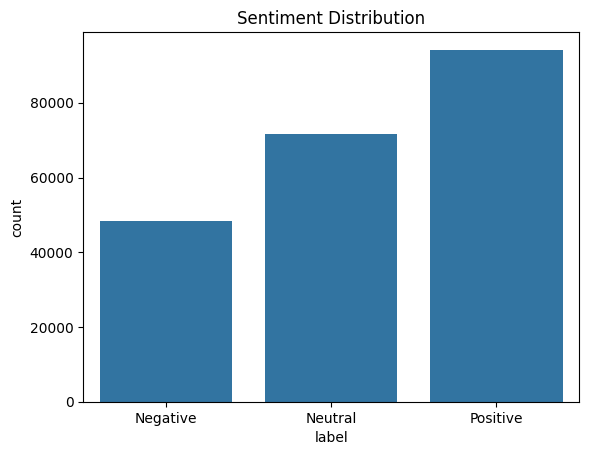

In [4]:
order = ["Negative", "Neutral", "Positive"]
sns.countplot(data=df, x="label", order=order)
plt.title("Sentiment Distribution"); plt.show()

In [5]:
nltk.download("stopwords"); nltk.download("wordnet"); nltk.download("punkt")
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop = set(stopwords.words("english")) - {"not", "no", "nor"}   # keep negations
lem = WordNetLemmatizer()

def clean(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)            # removes punctuation, curly quotes, digits
    tokens = [lem.lemmatize(w) for w in text.split() if w not in stop and len(w) > 1]
    return " ".join(tokens)

df["clean"] = df["Comment"].apply(clean)
df = df[df["clean"].str.strip() != ""].reset_index(drop=True)
df[["Comment", "clean"]].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


,Comment,clean
0,lets forget apple pay required brand new iphon...,let forget apple pay required brand new iphone...
1,nz retailers don’t even contactless credit car...,nz retailer even contactless credit card machi...
2,forever acknowledge channel help lessons ideas...,forever acknowledge channel help lesson idea e...
3,whenever go place doesn’t take apple pay doesn...,whenever go place take apple pay happen often ...
4,apple pay convenient secure easy use used kore...,apple pay convenient secure easy use used kore...


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)
X = tfidf.fit_transform(df["clean"])
y = df["Sentiment"]
print(X.shape)

(213883, 20000)


In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(171106, 20000) (42777, 20000)


In [11]:
print(X_train.shape, X_test.shape)

(171106, 20000) (42777, 20000)


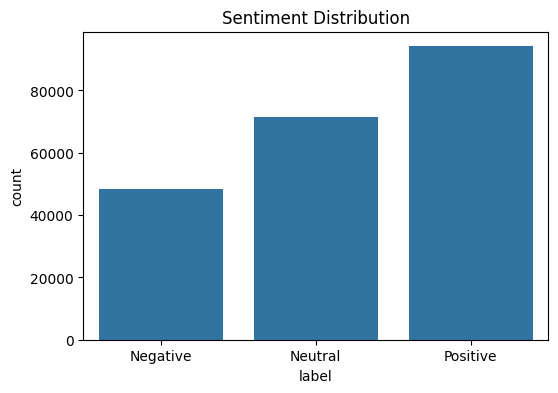

In [12]:
order = ["Negative", "Neutral", "Positive"]
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=order)
plt.title("Sentiment Distribution")
plt.show()

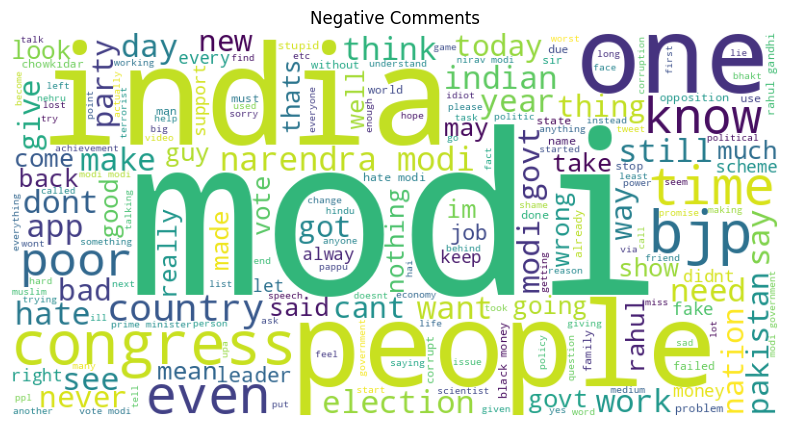

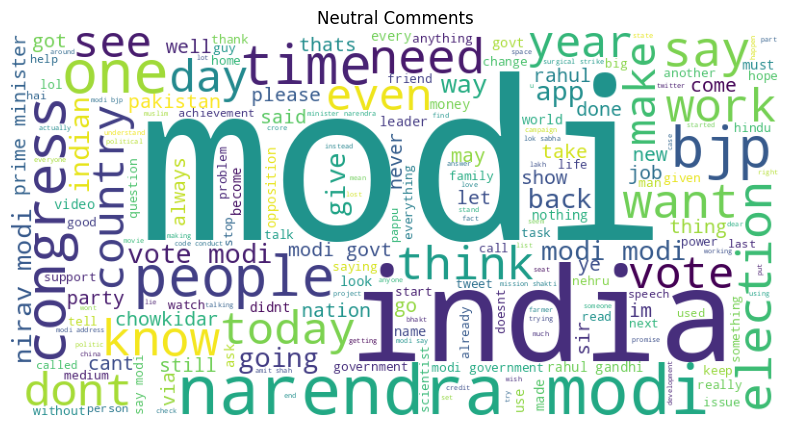

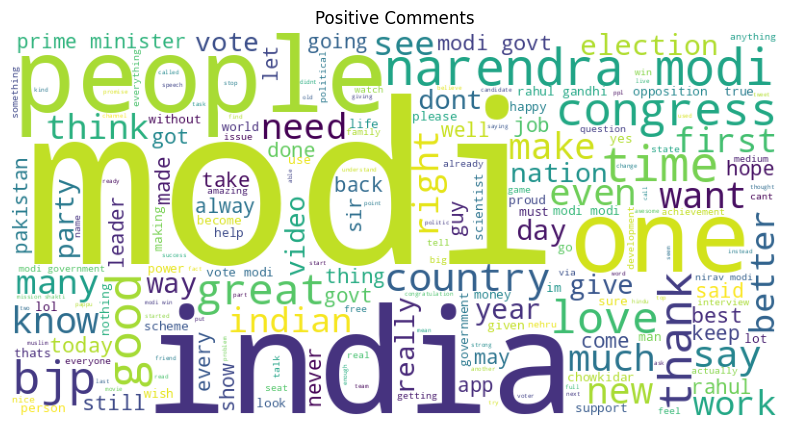

In [13]:
from wordcloud import WordCloud

for lbl in ["Negative", "Neutral", "Positive"]:
    text = " ".join(df[df["label"] == lbl]["clean"].sample(20000, random_state=1))
    wc = WordCloud(width=800, height=400, background_color="white").generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc)
    plt.axis("off")
    plt.title(f"{lbl} Comments")
    plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Split done:", X_train.shape, X_test.shape)

# Train
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, "trained")

Split done: (171106, 20000) (42777, 20000)
Naive Bayes trained
Logistic Regression trained
Linear SVM trained


## Conclusion

**Best model:** [model name] achieved the highest accuracy of [X]% and the best
weighted F1-score of [Y], compared with Naive Bayes ([A]%) and [other model] ([B]%).

**Why it performed well:** Linear models work well with high-dimensional TF-IDF
features, where most words are rare and the classes are largely linearly separable.

**Observations:**
- The Positive and Negative classes were predicted more reliably than Neutral.
- Neutral was the most confused class, since neutral comments often contain
  mildly positive or negative words.
- Error analysis showed mistakes caused by [mixed opinions / short text / negation].

**Real-world application:** This model could monitor customer opinion about a
product such as Apple Pay across social media, flag negative feedback for
support teams, and track brand sentiment over time.

**Limitations and future work:** Class imbalance (Negative is the smallest class)
and the inability to understand sarcasm or context. Future improvements include
class weighting and a transformer model such as BERT.